# Decision Trees Exercises


## Înainte de rulare
Am folosit fișierul `Wine_Quality_Data.csv` din folderul `data`. Celulele se rulează în ordine, de sus în jos. Sunt necesare numpy, pandas, matplotlib, seaborn, scikit-learn și IPython. Am păstrat `random_state=42` pentru a putea repeta experimentul cu aceeași împărțire a datelor. Pentru aceste exerciții nu este nevoie de sklearnex.


# Obiectivele cursului

- Recunoașteți arborii de decizie și modul în care aceștia pot fi utilizați pentru probleme de clasificare
- Aflați cum se determină cea mai bună divizare și factorii de divizare
- Explicați punctele forte și punctele slabe ale arborilor de decizie
- Explicați modul în care arborii de regresie ajută la clasificarea valorilor continue




## Introducere

Pentru aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține un indicator al calității (3-9, unde valoarea cea mai mare indică o calitate mai bună) și culoarea (roșu sau alb). Numele fișierului este „Wine_Quality_Data.csv”.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import make_pipeline
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 20)
data = pd.read_csv(Path('data') / 'Wine_Quality_Data.csv')
assert data.isna().sum().sum() == 0, 'Verificați valorile lipsă.'
assert set(data.color.unique()) == {'red', 'white'}
print('Dimensiune:', data.shape)
print('Valori lipsă:', data.isna().sum().sum())
print('Rânduri duplicate:', data.duplicated().sum())
display(data.head())
display(data.describe())


Dimensiune: (6497, 13)
Valori lipsă: 0
Rânduri duplicate: 1177


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


## Întrebarea 1

* Importați datele și studiați funcțiile.
* Le vom folosi pe toate pentru a prezice `color` (alb sau roșu), dar funcția culorilor trebuie codificată ca număr întreg.

Convertiți funcția de culoare într-un număr întreg. Iată o metodă rapidă de a face acest lucru folosind Pandas.

In [2]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
data['color_encoded'] = data.color.map({'white':0,'red':1})
X_cls = data.drop(columns=['color','color_encoded'])
y_cls = data.color_encoded
display(data.color.value_counts().to_frame('număr'))
display(X_cls.dtypes.to_frame('tip'))

,număr
color,
white,4898
red,1599


,tip
fixed_acidity,float64
volatile_acidity,float64
citric_acid,float64
residual_sugar,float64
chlorides,float64
free_sulfur_dioxide,float64
total_sulfur_dioxide,float64
density,float64
pH,float64
sulphates,float64


Am transformat culoarea în valori numerice: 0 pentru alb și 1 pentru roșu. Pentru predicție am păstrat toate cele 12 coloane numerice, inclusiv `quality`. Nu am scalat datele, deoarece arborele face separări după pragurile fiecărei caracteristici și nu calculează distanțe între observații.

## Întrebarea 2

* Utilizați `StratifiedShuffleSplit` pentru a împărți datele în seturi de trenuri și de teste, stratificate în funcție de calitatea vinului. Dacă este posibil, păstrați indicii privind ponderea pentru întrebarea 5 de mai jos.
* Verificați compoziția procentuală a fiecărui nivel de calitate pentru seturile de date privind trenurile și datele de testare.

In [3]:
splitter=StratifiedShuffleSplit(n_splits=1,test_size=.2,random_state=42)
train_idx,test_idx=next(splitter.split(X_cls,data.quality))
X_train,X_test=X_cls.iloc[train_idx],X_cls.iloc[test_idx]
y_train,y_test=y_cls.iloc[train_idx],y_cls.iloc[test_idx]
quality_distribution=pd.concat({
    'total_%':data.quality.value_counts(normalize=True)*100,
    'train_%':data.quality.iloc[train_idx].value_counts(normalize=True)*100,
    'test_%':data.quality.iloc[test_idx].value_counts(normalize=True)*100},axis=1).sort_index()
display(quality_distribution.round(3))
print('Antrenare:',len(train_idx),'Test:',len(test_idx))
print('Rânduri test identice cu cel puțin un rând train:',
      pd.util.hash_pandas_object(data.drop(columns='color_encoded').iloc[test_idx],index=False).isin(
      pd.util.hash_pandas_object(data.drop(columns='color_encoded').iloc[train_idx],index=False)).sum())

Antrenare: 5197 Test: 1300
Rânduri test identice cu cel puțin un rând train: 357


,total_%,train_%,test_%
quality,,,
3,0.462,0.462,0.462
4,3.325,3.329,3.308
5,32.907,32.904,32.923
6,43.651,43.660,43.615
7,16.608,16.606,16.615
8,2.971,2.963,3.000
9,0.077,0.077,0.077


Am împărțit datele în 80% pentru antrenare și 20% pentru test, păstrând aproximativ proporția fiecărui nivel de calitate. Procentele din tabel sunt apropiate; micile diferențe apar fiindcă numărul de observații trebuie să fie întreg. Am salvat indicii pentru a folosi aceeași împărțire și la regresie.

În date sunt 1.177 de rânduri duplicate. După împărțire, 357 de rânduri din test au un corespondent identic în train. Acest lucru poate face scorurile să pară mai bune. Am păstrat datele pentru a urma exercițiul, dar pentru o evaluare mai strictă ar trebui eliminate duplicatele sau ținute în același subset.

## Întrebarea 3

* Construiți un clasificator pe baza unui arbore de decizie, fără restricții privind adâncimea maximă, numărul de caracteristici sau numărul de frunze.
* Determinați câte noduri sunt prezente în acest arbore (foarte mare) și care este adâncimea acestuia.
* Folosind acest arbore, evaluați eroarea de predicție pe seturile de date de antrenare și de testare. Ce credeți că se întâmplă aici, pe baza diferențelor dintre erorile de predicție?

In [4]:
unrestricted_tree=DecisionTreeClassifier(random_state=42)
unrestricted_tree.fit(X_train,y_train)
def classification_results(model,name):
    rows=[]
    for split,xx,yy in [('train',X_train,y_train),('test',X_test,y_test)]:
        pred=model.predict(xx)
        rows.append({'model':name,'set':split,'eroare':1-accuracy_score(yy,pred),
                     'accuracy':accuracy_score(yy,pred),'precision_red':precision_score(yy,pred,zero_division=0),
                     'recall_red':recall_score(yy,pred,zero_division=0),'F1_red':f1_score(yy,pred,zero_division=0)})
    return pd.DataFrame(rows)
print('Noduri:',unrestricted_tree.tree_.node_count,'Adâncime:',unrestricted_tree.get_depth())
baseline=classification_results(unrestricted_tree,'fără restricții')
display(baseline)
print('Diferență eroare test - train:',baseline.iloc[1].eroare-baseline.iloc[0].eroare)

Noduri: 151 Adâncime: 21
Diferență eroare test - train: 0.014230547209188704


,model,set,eroare,accuracy,precision_red,recall_red,F1_red
0,fără restricții,train,0.000385,0.999615,0.999227,0.999227,0.999227
1,fără restricții,test,0.014615,0.985385,0.964401,0.973856,0.969106


Arborele fără restricții a ajuns la 151 de noduri și o adâncime de 21. Eroarea pe test este cu aproximativ 1,42 puncte procentuale mai mare decât pe antrenare. Această diferență sugerează supraînvățare: arborele se potrivește foarte bine pe datele cunoscute, dar face mai multe greșeli pe cele din test.

Am calculat eroarea ca `1 − acuratețe`. Pentru precizie, recall și F1 am considerat vinul roșu drept clasa pozitivă.

## Întrebarea 4

* Folosind metoda de căutare în rețea cu validare încrucișată, găsiți un arbore de decizie care să dea rezultate bune pe setul de date de testare. Atribuiți acestui model de arbore de decizie un alt nume de variabilă decât cel din întrebarea 3, astfel încât ambele modele să poată fi utilizate la întrebarea 6.
* Determinați numărul de noduri și adâncimea acestui arbore.
* Calculați erorile pe seturile de date de antrenament și de testare, la fel ca mai devreme, și comparați-le cu erorile arborelui din întrebarea 3.

In [5]:
cv_cls=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
param_grid={'max_depth':[3,5,8,None],'min_samples_leaf':[1,5,15],
            'max_features':[None,'sqrt']}
search_cls=GridSearchCV(DecisionTreeClassifier(random_state=42),param_grid,
                        scoring='accuracy',cv=cv_cls,n_jobs=1)
search_cls.fit(X_train,y_train)
tuned_tree=search_cls.best_estimator_
print('Parametri optimi:',search_cls.best_params_)
print('Acuratețe medie CV:',search_cls.best_score_)
print('Noduri:',tuned_tree.tree_.node_count,'Adâncime:',tuned_tree.get_depth())
comparison=pd.concat([baseline,classification_results(tuned_tree,'optimizat CV')],ignore_index=True)
display(comparison)
print('Diferență eroare test optimizat - inițial:',
      comparison.iloc[3].eroare-comparison.iloc[1].eroare)

Parametri optimi: {'max_depth': 8, 'max_features': None, 'min_samples_leaf': 1}
Acuratețe medie CV: 0.9851852743022137
Noduri: 77 Adâncime: 8
Diferență eroare test optimizat - inițial: 0.0


,model,set,eroare,accuracy,precision_red,recall_red,F1_red
0,fără restricții,train,0.000385,0.999615,0.999227,0.999227,0.999227
1,fără restricții,test,0.014615,0.985385,0.964401,0.973856,0.969106
2,optimizat CV,train,0.005195,0.994805,0.996082,0.982985,0.989490
3,optimizat CV,test,0.014615,0.985385,0.976744,0.960784,0.968699


Am ales parametrii cu GridSearchCV, folosind cinci împărțiri de validare doar în setul de antrenare. Cea mai bună variantă găsită are `max_depth=8`, `min_samples_leaf=1` și folosește toate caracteristicile la fiecare separare. Acuratețea medie pe validare a fost de aproximativ 98,52%.

Arborele obținut are 77 de noduri, față de 151 inițial, iar adâncimea a scăzut de la 21 la 8. Pe test, eroarea a rămas aceeași. În acest caz am obținut un arbore mai simplu, cu aceeași performanță pe test. Setul de test a fost folosit abia după alegerea parametrilor.

## Întrebarea 5

* Împărțiți din nou datele în părțile `X` și `y`, de data aceasta cu `residual_sugar` ca date de predicție (`y`). *Notă:* dacă indicii au fost salvați din rezultatele `StratifiedShuffleSplit` din întrebarea 2, aceștia pot fi reutilizați pentru împărțirea datelor.
* Folosind căutarea pe grilă cu validare încrucișată, găsiți un model de **regresie** bazat pe un arbore de decizie care să funcționeze bine pe setul de date de testare.
* Evaluați erorile pe seturile de date de antrenare și de testare folosind eroarea medie pătratică.
* Realizați un grafic care să prezinte atât valorile reale, cât și cele previzionate ale zahărului rezidual.

Parametri optimi: {'max_depth': None, 'max_features': None, 'min_samples_leaf': 5}
MSE mediu CV: 3.1441035264205555
MSE train: 0.8299029530162395
MSE test: 3.038730455594257
RMSE test: 1.7431954725716383
MSE reper (media train): 21.58448967589234


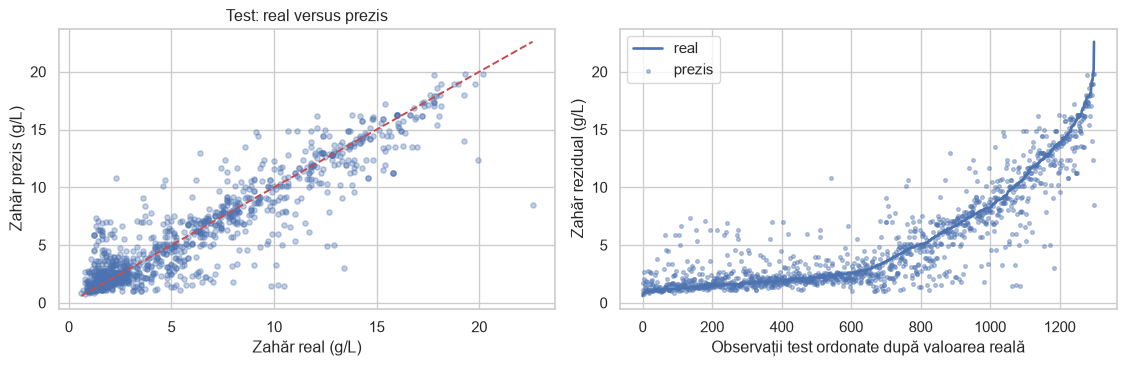

In [6]:
X_reg=data.drop(columns=['residual_sugar','color'])
y_reg=data.residual_sugar
# Păstrez culoarea codificată în X și scot zahărul rezidual, fiindcă acum este ținta.
Xr_train,Xr_test=X_reg.iloc[train_idx],X_reg.iloc[test_idx]
yr_train,yr_test=y_reg.iloc[train_idx],y_reg.iloc[test_idx]
cv_reg=KFold(n_splits=5,shuffle=True,random_state=42)
search_reg=GridSearchCV(DecisionTreeRegressor(random_state=42),
    {'max_depth':[3,5,8,None],'min_samples_leaf':[1,5,15],'max_features':[None,'sqrt']},
    scoring='neg_mean_squared_error',cv=cv_reg,n_jobs=1)
search_reg.fit(Xr_train,yr_train)
reg_tree=search_reg.best_estimator_
pred_train=reg_tree.predict(Xr_train)
pred_test=reg_tree.predict(Xr_test)
print('Parametri optimi:',search_reg.best_params_)
print('MSE mediu CV:',-search_reg.best_score_)
print('MSE train:',mean_squared_error(yr_train,pred_train))
print('MSE test:',mean_squared_error(yr_test,pred_test))
print('RMSE test:',np.sqrt(mean_squared_error(yr_test,pred_test)))
print('MSE reper (media train):',mean_squared_error(yr_test,np.full(len(yr_test),yr_train.mean())))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(yr_test,pred_test,alpha=.35,s=16)
lims=[min(yr_test.min(),pred_test.min()),max(yr_test.max(),pred_test.max())]
axes[0].plot(lims,lims,'r--')
axes[0].set(xlabel='Zahăr real (g/L)',ylabel='Zahăr prezis (g/L)',title='Test: real versus prezis')
order=np.argsort(yr_test.to_numpy())
axes[1].plot(yr_test.to_numpy()[order],label='real',linewidth=2)
axes[1].scatter(np.arange(len(order)),pred_test[order],s=8,alpha=.4,label='prezis')
axes[1].set(xlabel='Observații test ordonate după valoarea reală',ylabel='Zahăr rezidual (g/L)')
axes[1].legend(); plt.tight_layout(); plt.show()

Pentru regresie, ținta este cantitatea de zahăr rezidual. Am obținut un MSE de aproximativ 0,83 pe antrenare și 3,04 pe test. Diferența arată că modelul se potrivește mai bine pe datele de antrenare. Totuși, pe test este mult mai bun decât varianta care prezice mereu media din train, pentru care MSE este aproximativ 21,58.

RMSE pe test este de aproximativ 1,74 g/L. Această valoare exprimă eroarea în aceeași unitate ca zahărul rezidual. În primul grafic, predicțiile bune sunt aproape de diagonala roșie. În al doilea am ordonat observațiile după valoarea reală, pentru a compara mai ușor valorile reale cu cele prezise. Erorile mari influențează mai puternic MSE, deoarece diferențele sunt ridicate la pătrat.

## Întrebarea 6 *(Opțională)*

Această întrebare este opțională, deoarece pentru rezolvarea ei este necesar un program suplimentar de linie de comandă (GraphViz) și o bibliotecă Python (PyDotPlus). GraphViz poate fi instalat cu ajutorul managerului de pachete pe Linux și Mac. Pentru instalarea bibliotecii PyDotPlus se poate folosi fie `pip`, fie `conda` (`conda install -c conda-forge pydotplus`).

După instalarea acestor programe:

* Creați o vizualizare a arborelui de decizii din întrebarea 3, în care s-a prezis culoarea vinului, iar numărul de caracteristici și/sau diviziuni nu este limitat.
* Creați o vizualizare a arborelui de decizie din întrebarea 4, în care s-a prezis culoarea vinului, dar pentru a găsi adâncimea optimă și numărul optim de caracteristici s-a utilizat căutarea pe grilă.

Arborele de decizie din întrebarea 5 va avea, cel mai probabil, prea multe noduri pentru a putea fi vizualizat.

initial : structură completă exportată în DOT; 151 noduri
optimizat : structură completă exportată în DOT; 77 noduri


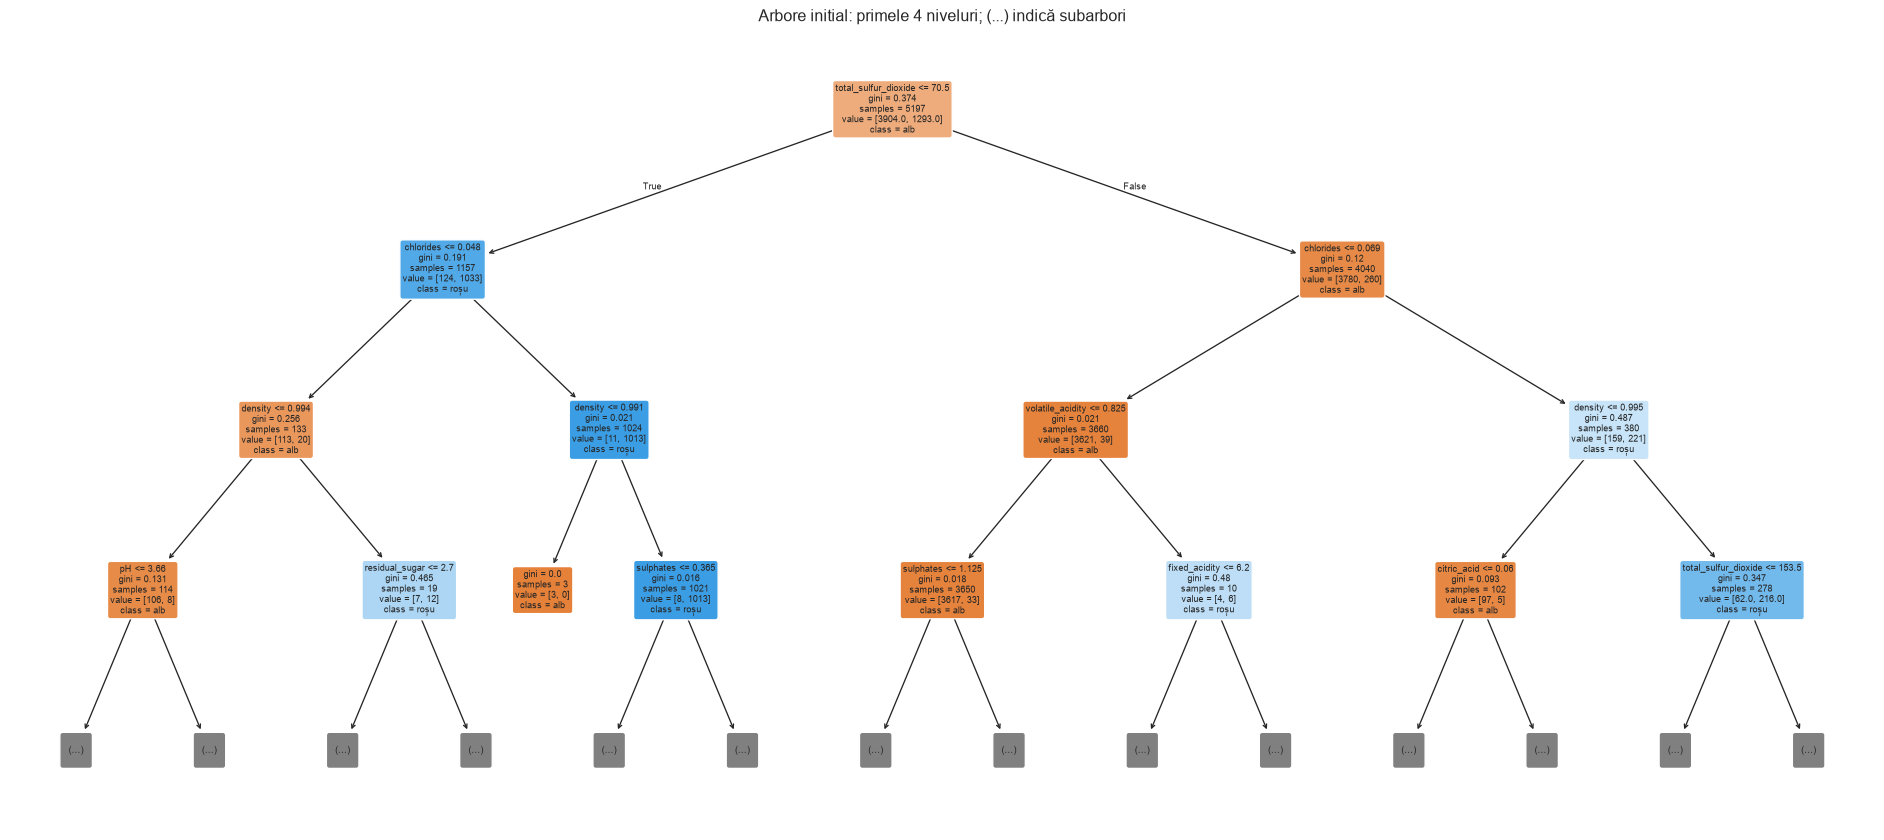

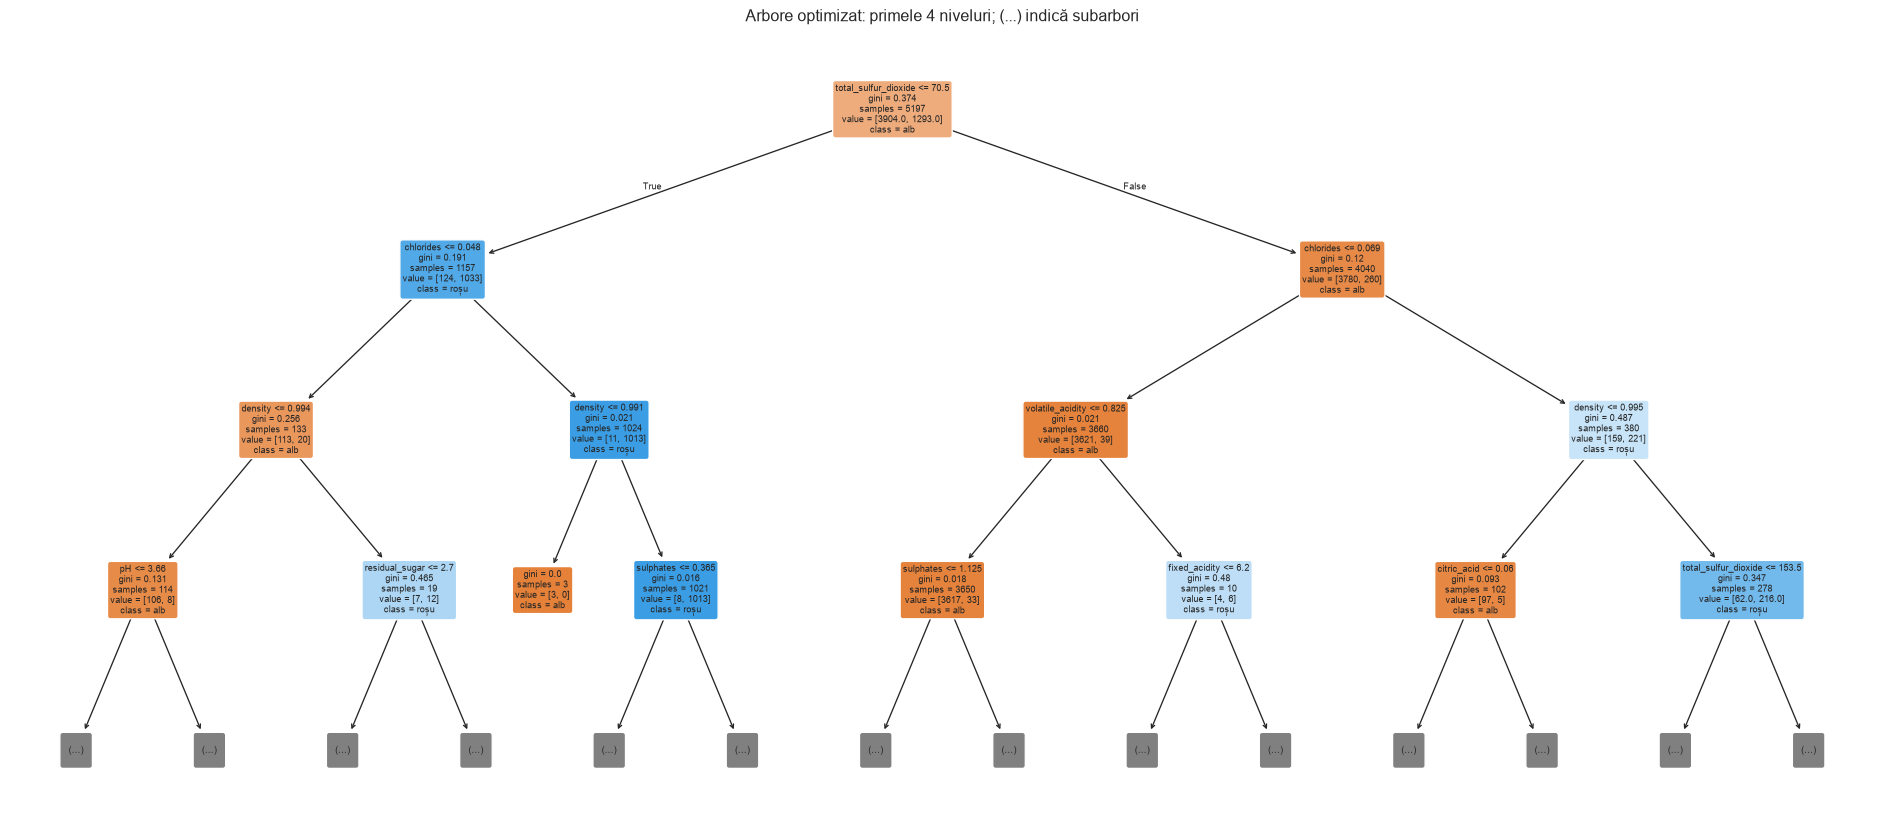

In [7]:
# Desenez arborii cu plot_tree, fără să mai instalez GraphViz sau PyDotPlus.
for name,model in [('initial',unrestricted_tree),('optimizat',tuned_tree)]:
    fig,ax=plt.subplots(figsize=(20,9))
    plot_tree(model,max_depth=3,feature_names=X_cls.columns.tolist(),
              class_names=['alb','roșu'],filled=True,rounded=True,fontsize=7,ax=ax)
    ax.set_title(f'Arbore {name}: primele 4 niveluri; (...) indică subarbori')
    plt.tight_layout(); plt.show()
    export_graphviz(model,out_file=f'arbore_{name}_complet.dot',
        feature_names=X_cls.columns.tolist(),class_names=['alb','roșu'],filled=True,rounded=True)
    print(name, ': structură completă exportată în DOT;', model.tree_.node_count,'noduri')

Am desenat primele patru niveluri ale fiecărui arbore, ca să se poată citi condițiile din noduri. Semnul (...) arată că arborele continuă mai jos. Fiecare nod afișează condiția de separare, impuritatea Gini, numărul de exemple și clasa majoritară.

Am salvat și arborii compleți în fișierele DOT. Pentru imaginea completă se poate folosi GraphViz, de exemplu: `dot -Tsvg arbore_initial_complet.dot -o arbore_initial_complet.svg`. Pentru graficele din notebook am folosit `plot_tree`, care nu cere instalarea GraphViz sau PyDotPlus.

## Rezultatele obținute

Am păstrat mai jos valorile obținute la rulare. Timpii de antrenare pot varia dacă repet experimentul.

```text
Noduri: 151 Adâncime: 21
Diferență eroare test - train: 0.014230547209188704

Parametri optimi: {'max_depth': 8, 'max_features': None, 'min_samples_leaf': 1}
Acuratețe medie CV: 0.9851852743022137
Noduri: 77 Adâncime: 8
Diferență eroare test optimizat - inițial: 0.0

Parametri optimi: {'max_depth': None, 'max_features': None, 'min_samples_leaf': 5}
MSE mediu CV: 3.1441035264205555
MSE train: 0.8299029530162395
MSE test: 3.038730455594257
RMSE test: 1.7431954725716383
MSE reper (media train): 21.58448967589234
```